# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 1: Reconstrucción de una imagen

**Grupo:** 10

**Integrantes:**
- Lucas Martín Chicao Carmona
- Ignacio Andrés Osorio Orellana
- Martín Ignacio Serrano Pizarro
- Martin Antonio Von Gehr Campos

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). En este problema, excepcionalmente, pueden usar `np.linalg.solve` en (b), (c) y (d).
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

FIGURAS = "../informe/figuras"   # el informe toma las figuras directamente desde aquí
os.makedirs(FIGURAS, exist_ok=True)

## Datos

El archivo `datos_P1.npz` debe estar en la misma carpeta que este notebook.

In [2]:
datos = np.load("datos_P1.npz")
A = datos["A"]          # matriz de desenfoque (n x n)
b = datos["b"]          # imagen observada
b_def = datos["b_def"]  # imagen observada con píxeles dañados, para (d)

n = b.size
N = int(np.sqrt(n))
sigma = 0.01
delta = sigma * np.sqrt(n)
print(f"A: {A.shape},  b: {b.shape},  b_def: {b_def.shape},  N = {N},  delta = {delta:.2f}")

A: (4096, 4096),  b: (4096,),  b_def: (4096,),  N = 64,  delta = 0.64


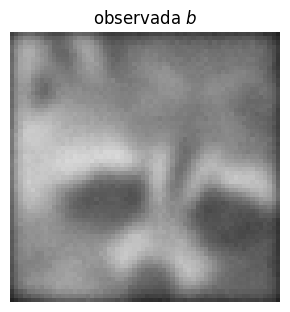

In [3]:
def mostrar(imagenes, titulos, archivo=None):
    """Muestra vectores de largo n como imágenes de N x N, lado a lado (valores fuera de [0, 1] se recortan)."""
    fig, axs = plt.subplots(1, len(imagenes), figsize=(3 * len(imagenes), 3.2))
    axs = np.atleast_1d(axs)
    for ax, v, t in zip(axs, imagenes, titulos):
        ax.imshow(v.reshape(N, N), cmap="gray", vmin=0, vmax=1)
        ax.set_title(t)
        ax.axis("off")
    fig.tight_layout()
    if archivo is not None:
        fig.savefig(os.path.join(FIGURAS, archivo), dpi=200, bbox_inches="tight")
    plt.show()


mostrar([b], ["observada $b$"], archivo="ejemplo_b.png")

## (a) Mínimos cuadrados

# Esta en el PDF correspondiente

## (b) Reconstrucción

### i. Implementación

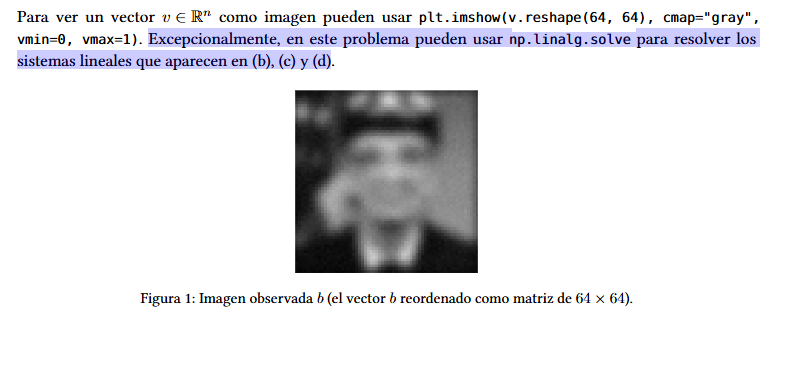

x0 =  [   22.40087367  1791.86906738 -4831.05959819 ...  4686.13426262
 -4895.73121043  2099.22454833]
Norma ||x0||_2: 350302.18
Máximo absoluto max_i |x0_i|: 1.87e+04
Residuo ||A x0 - b||_2: 5.57e-12


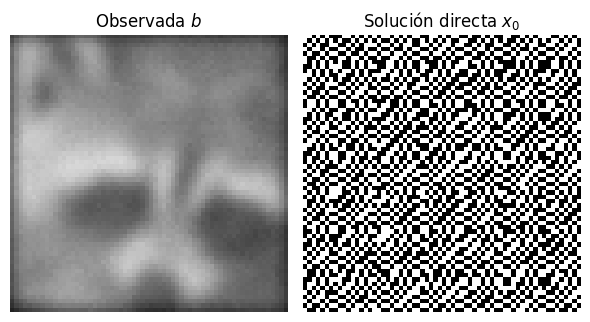

In [ ]:
# TODO
# - Calcular x0 resolviendo Ax = b.
# - Reportar ||x0||_2, max_i |x0_i| y el residuo ||A x0 - b||_2.
# - Mostrar b y x0 lado a lado: mostrar([...], [...], archivo="P1_b_reconstruccion.png")


A = datos["A"]          
b = datos["b"]          
x0 = np.linalg.solve(A,b) 
print("x0 = ",x0)
print("b = ",b)

norma_x0 = np.linalg.norm(x0)
max_abs_x0 = np.max(np.abs(x0))
residuo_x0 = np.linalg.norm(A @ x0 - b)

print(f"Norma ||x0||_2: {norma_x0:.2f}")
print(f"Máximo absoluto max_i |x0_i|: {max_abs_x0:.2e}")
print(f"Residuo ||A x0 - b||_2: {residuo_x0:.2e}")

mostrar(
    imagenes=[b, x0], 
    titulos=["Observada $b$", "Solución directa $x_0$"], 
    archivo="P1_b_reconstruccion.png"
)


### ii. Explicación

## (c) Regularización de Tikhonov

### iv. Implementación

In [ ]:
# TODO
# - Calcular x_lambda resolviendo (A^T A + lambda I) x = A^T b para lambda en {10^-3.5, 10^-2.5, 1}.
# - Reportar la norma y el residuo ||Ax - b||_2 de cada reconstrucción y compararlos con delta.
# - Mostrar b, x0 y las tres x_lambda en una figura: archivo="P1_c_tikhonov.png"

## (d) Píxeles dañados

In [ ]:
# TODO
# - Reconstruir la imagen a partir de b_def con Tikhonov y lambda = 10^-2.5.
# - Mostrar b_def y la reconstrucción lado a lado: archivo="P1_d_danados.png"

### ii. $\|\tilde{b} - b\|_2$

In [ ]:
# TODO
# - Calcular ||b_def - b||_2 y comparar la norma del nuevo ruido con delta.

## (Bonus) Mínimos cuadrados ponderados

In [ ]:
# TODO
# - Implementar la reconstrucción que minimiza J_W, con W = diag(w) y w_p = 0 si el píxel p está dañado.
# - Mostrar el resultado: archivo="P1_bonus_ponderados.png"